In [1]:
import warnings

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import auc, confusion_matrix, f1_score, recall_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils import shuffle as sk_shuffle
from toolbox import (
    Masking,
    augment_patient_and_cat_specific,
    find_all_indices,
    hot_coding,
    visualize_Category_hist,
)
from toolbox.loading import load_data

In [2]:
# load masking
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)
# set prints off
mask.prints = False

__IIVV-results from statistical evaluation__

## Contents

- SNR Data augmentation tuning
- Model tuning
    - SVM tuning
    - RF tuning
    - LR tuning



**Data loading**

In [3]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    Avg_Cutpats,
    LesionAssessment,
    labels_healthy_vs_cancer,
    labels_hr_vs_lr,
    labels_MC,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 


**Select classification basis task `class_task`**

- `"healthy_vs_cancer"`
- `"hr_vs_lr"`
- `"MC"`

In [3]:
class_task = "healthy_vs_cancer"
# class_task = "hr_vs_lr"
# class_task = "MC"

data_augmentation = False

Healthy vs. cancer

Healthy: 90 entries
Cancer: 96 entries
Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{'Cancer': [1, 0], 'Healthy': [0, 1]}


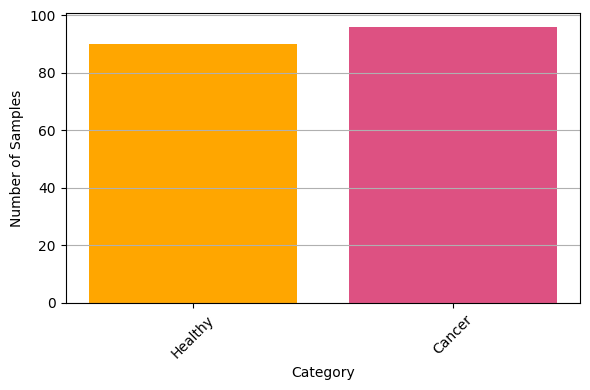


Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Healthy'}
(186, 31, 7728) (186, 2) (186,)


In [5]:
if class_task == "healthy_vs_cancer":
    print("Healthy vs. cancer\n")
    select_idx = find_all_indices(
        labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
    )
    labels = labels_healthy_vs_cancer[select_idx]
    Y, inverse_mapping = hot_coding(labels)
    # for SVD kernel boundary
    Y_labels = np.argmax(Y, axis=1)
    cp = {
        1: "#003F5C",  # healthy
        0: "#FFA600",  # cancer
    }
    cp_l = {
        1: "healthy",  # healthy
        0: "cancer",  # cancer
    }
    visualize_Category_hist(labels)

elif class_task == "hr_vs_lr":
    print("\nHealthy vs. LR vs. HR\n")
    select_idx = find_all_indices(
        labels_hr_vs_lr, ["High risk", "Low risk"], split=False
    )
    labels = labels_hr_vs_lr[select_idx]
    Y, inverse_mapping = hot_coding(labels)
    Y_labels = np.argmax(Y, axis=1)
    cp = {
        0: "#FF6361",  # "High risk
        1: "#58508D",  # "Low risk
    }
    cp_l = {
        0: "High risk",  # High risk
        1: "Low risk",  # Low risk
    }
    visualize_Category_hist(labels)

elif class_task == "MC":
    print("\nMC\n")
    select_idx = find_all_indices(
        labels_MC,
        ["Healthy", "Cancer", "High-grade dysplasia", "Non-malignant"],
        split=False,
    )
    labels = labels_MC[select_idx]
    Y, inverse_mapping = hot_coding(labels)
    Y_labels = np.argmax(Y, axis=1)
    cp = {
        0: "#58508D",  # Non-malignant
        1: "#FFA600",  # Cancer
        2: "#003F5C",  # Healthy
        3: "#FF6361",  # High-grade dysplasia
    }
    cp_l = {
        0: "Non-malignant",
        1: "Cancer",
        2: "Healthy",
        3: "High-grade dysplasia",
    }
    aug_dict = {
        "High-grade dysplasia": 70,
        "Non-malignant": 70,
    }

Case = patient_no[select_idx]
X = Zdata[select_idx, ...]
print("\nInverse mapping:", inverse_mapping)
print(X.shape, Y.shape, Case.shape)

if class_task == "MC" and data_augmentation:
    print("\n\t\tBefore augmentation")
    visualize_Category_hist(labels)
    X, Y_labels, labels, Case = augment_patient_and_cat_specific(
        X, Y_labels, labels, Case, aug_dict
    )
    print("\n\t\tAfter augmentation")
    visualize_Category_hist(labels)

# Model tuning

**Tuning using `GridSearch()` with `GroupKFold()` train/test data split**

- SVM tuning
- RF tuning
- LR tuning

In [6]:
n_folds = 5  # number of iterations inside each LPOCV
output_prints = False

# load frequency selection
tmp = np.load(f"results/freq_fold_results_{class_task}.npz", allow_pickle=True)
top_freqs_baseline = tmp["top_freqs_baseline"]
print(f"{top_freqs_baseline=}")
# Top frequency groups for Task 1: 5,6,8,7, Task 2: 4,2,29,27, Task 3: 23,28,24,27

if class_task == "healthy_vs_cancer":
    print("Task 1: 6,14,5,7")
    Freq_sel = {
        "Top 6": top_freqs_baseline[:6],
        "Top 14": top_freqs_baseline[:14],
        "Top 5": top_freqs_baseline[:5],
        "Top 7": top_freqs_baseline[:7],
        # "All": top_freqs_baseline,  # np.arange(31),
    }
elif class_task == "cancer_vs_hbd":
    print("Task 2: 3,4,2,5")
    Freq_sel = {
        "Top 3": top_freqs_baseline[:3],
        "Top 4": top_freqs_baseline[:4],
        "Top 2": top_freqs_baseline[:2],
        "Top 5": top_freqs_baseline[:5],
        # "All": top_freqs_baseline,  # np.arange(31),
    }
elif class_task == "cancer_vs_lr_hr":
    print("Task 2: 4,2,29,17")
    Freq_sel = {
        "Top 4": top_freqs_baseline[:4],
        "Top 2": top_freqs_baseline[:2],
        "Top 29": top_freqs_baseline[:29],
        "Top 17": top_freqs_baseline[:17],
        # "All": top_freqs_baseline,  # np.arange(31),
    }
elif class_task == "hr_vs_lr":
    print("Task 2: 30,3,27,28")
    Freq_sel = {
        "Top 30": top_freqs_baseline[:30],
        "Top 3": top_freqs_baseline[:3],
        "Top 27": top_freqs_baseline[:27],
        "Top 28": top_freqs_baseline[:28],
        # "All": top_freqs_baseline,  # np.arange(31),
    }
if class_task == "MC":
    print("Task 3: 13,19,20,18")
    Freq_sel = {
        "Top 13": top_freqs_baseline[:13],
        "Top 19": top_freqs_baseline[:19],
        "Top 20": top_freqs_baseline[20],
        "Top 18": top_freqs_baseline[:18],
        # "All": top_freqs_baseline,  # np.arange(31),
    }

# load masking selection
tmp = np.load(f"results/Top_IIVV_masks_{class_task}.npz", allow_pickle=True)
Mask_ranks = tmp["Mask_ranks"][:4]

Mask_sel = {
    "All": "all",
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Skip1 close": "vv_distance_close_skip_1",
    "Adj. close": "adjacent_close",
    "Med. adj.": "vv_distance_medium_adj",
    "Adj. far": "adjacent_far",
    "Skip1 medium": "skip1_medium",
    "Skip1 far": "skip1_far",
    "Opp. close": "opposite_close",
    "Opp. medium": "opposite_medium",
    "Opp. far": "opposite_far",
}
Mask_sel = {k: v for k, v in Mask_sel.items() if k in Mask_ranks}
print(Mask_sel)

top_freqs_baseline=array([30, 27,  0, 29, 12, 13,  8, 28, 26, 16, 25, 17,  1, 10, 24, 20, 11,
        9, 21, 22,  3, 15, 23,  5,  4, 19, 14, 18,  6,  2,  7])
Task 1: 6,14,5,7
{'Adj. far': 'adjacent_far', 'Skip1 far': 'skip1_far', 'Opp. medium': 'opposite_medium'}


In [7]:
# Z-thresholding selection

# load in average impedances
avg_Z_fp = np.load("source/Avg_Zs.npy")

if class_task == "healthy_vs_cancer":
    print("Task 1 Z-threshold: 386")
    z_thresh = 386
elif class_task == "hr_vs_lr":
    print("Task 2 Z-threshold: 423")
    z_thresh = 423
elif class_task == "MC":
    print("Task 3 Z-threshold: 592")
    z_thresh = 592

Msel = f"z_threshold: {z_thresh}"

Task 1 Z-threshold: 386


## SVM tuning

In [ ]:
stats_df = []
use_model = "SVM"

param_grid = {
    "kernel": ["linear", "poly", "rbf", "sigmoid"],
    "C": np.logspace(-3, 3, 7, dtype=float),  # [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}
for Fsel in Freq_sel.keys():
    for random_state in range(10):

        cv = GroupKFold(n_splits=n_folds, random_state=random_state, shuffle=True)
        """
        for fold, (train_idx, test_idx) in enumerate(cv.split(X_tmp, Y_labels, groups=Case), 1):
            print(f"Fold {fold}")
            print("  Train groups:", Case[train_idx])
            print("  Test groups :", Case[test_idx])
            print("  Train idx   :", train_idx)
            print("  Test idx    :", test_idx)
            print()
        """
        m = SVC(probability=True, random_state=random_state)

        grid_search = GridSearchCV(
            estimator=m,
            param_grid=param_grid,
            cv=cv,
            scoring="roc_auc_ovr",
            n_jobs=10,
        )

        # select freq and IIVV and shape data
        X_tmp = X[:, Freq_sel[Fsel], :]

        # Select columns/patterns for this threshold
        above_threshold = avg_Z_fp[0, :] <= z_thresh
        X_tmp = X_tmp[:, :, above_threshold]
        X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)

        grid_search.fit(X_tmp, Y_labels, groups=Case)

        best_params = grid_search.best_params_
        best_score = grid_search.best_score_

        if output_prints:
            print(f"\nRandom_state{random_state}")
            print("Best parameters:", best_params)
            print("Best ROC AUC:", best_score)

        df_row = {
            "Architecture": use_model,
            "Fsel": Fsel,
            "Msel": Msel,
            "n_params": X_tmp.shape[1],
            "Random_state": random_state,
            "val AUC": best_score,
        }
        df_row.update(best_params)
        stats_df.append(df_row)

df = pd.DataFrame(stats_df)
df.to_csv(f"results/LPOCV_tuning_SVM_z_thresh_{class_task}.csv", index=False)

In [4]:
param_grid = {
    "kernel": ["linear", "poly", "rbf", "sigmoid"],
    "C": np.logspace(-3, 3, 7, dtype=float),  # [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}
keys = list(param_grid.keys())

df = pd.read_csv(f"results/LPOCV_tuning_SVM_z_thresh_{class_task}.csv")

In [5]:
df["hpt_combinations"] = df.apply(
    lambda row: "_".join([str(row[k]) for k in keys]), axis=1
)

result = df.groupby("hpt_combinations")["val AUC"].mean().reset_index()
print(result)

for col in ["hpt_combinations"]:
    print(f"\nColumn: {col}")
    print(df[col].value_counts())

  hpt_combinations   val AUC
0     linear_0.001  0.905766
1        poly_0.01  0.895483
2         poly_0.1  0.901190
3          rbf_1.0  0.902402
4         rbf_10.0  0.880604

Column: hpt_combinations
hpt_combinations
rbf_1.0         14
poly_0.1        12
poly_0.01       12
rbf_10.0         1
linear_0.001     1
Name: count, dtype: int64


[Plot-svm-kernels](https://scikit-learn.org/stable/auto_examples/svm/plot_svm_kernels.html#rbf-kernel)

In [ ]:
C_val = 10

X_flat = X.reshape(X.shape[0], -1)
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_flat)

kernels = ["linear", "rbf", "poly", "sigmoid"]
colors = [cp[label] for label in Y_labels]
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
axes = axes.ravel()
for i, kernel in enumerate(kernels):
    clf = SVC(kernel=kernel, C=10)
    clf.fit(X_2d, Y_labels)

    x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
    y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    axes[i].contourf(xx, yy, -1 * Z, alpha=0.2)
    scatter = axes[i].scatter(X_2d[:, 0], X_2d[:, 1], c=colors, edgecolor="k")
    axes[i].set_title(f"{kernel}")
    legend_handles = [mpatches.Patch(color=cp[k], label=cp_l[k]) for k in cp.keys()]
fig.legend(handles=legend_handles, loc="upper center", ncol=2, frameon=True)

plt.tight_layout()
plt.savefig(
    f"results/SVM_kernels_z_thresh_{class_task}_{C_val}.pdf",
    bbox_inches="tight",
)
plt.show()

In [ ]:
C_val = 1000

X_flat = X.reshape(X.shape[0], -1)
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_flat)

kernels = ["linear", "rbf", "poly", "sigmoid"]
colors = [cp[label] for label in Y_labels]
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
axes = axes.ravel()
for i, kernel in enumerate(kernels):
    clf = SVC(kernel=kernel, C=10)
    clf.fit(X_2d, Y_labels)

    x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
    y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    axes[i].contourf(xx, yy, -1 * Z, alpha=0.2)
    scatter = axes[i].scatter(X_2d[:, 0], X_2d[:, 1], c=colors, edgecolor="k")
    axes[i].set_title(f"{kernel}")
    legend_handles = [mpatches.Patch(color=cp[k], label=cp_l[k]) for k in cp.keys()]
fig.legend(handles=legend_handles, loc="upper center", ncol=2, frameon=True)

plt.tight_layout()
plt.savefig(
    f"results/SVM_kernels_z_thresh_{class_task}_{C_val}.pdf",
    bbox_inches="tight",
)
plt.show()

## RF tuning

In [ ]:
stats_df = []
use_model = "RF"

param_grid = {
    "n_estimators": [100, 300, 500],
    "max_depth": [510, 20, None],
    "max_features": ["sqrt", "log2"],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2, 4],
}
for Fsel in Freq_sel.keys():
    for random_state in range(10):
        cv = GroupKFold(n_splits=n_folds, random_state=random_state, shuffle=True)

        m = RandomForestClassifier(random_state=random_state)

        grid_search = GridSearchCV(
            estimator=m,
            param_grid=param_grid,
            cv=cv,
            scoring="roc_auc_ovr",
            n_jobs=10,
        )

        # select freq and IIVV and shape data
        X_tmp = X[:, Freq_sel[Fsel], :]

        # Select columns/patterns for this threshold
        above_threshold = avg_Z_fp[0, :] <= z_thresh
        X_tmp = X_tmp[:, :, above_threshold]
        X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)

        grid_search.fit(X_tmp, Y_labels, groups=Case)

        best_params = grid_search.best_params_
        best_score = grid_search.best_score_

        if output_prints:
            print(f"\nRandom_state{random_state}")
            print("Best parameters:", best_params)
            print("Best ROC AUC:", best_score)

        df_row = {
            "Architecture": use_model,
            "Fsel": Fsel,
            "Msel": Msel,
            "n_params": X_tmp.shape[1],
            "Random_state": random_state,
            "val AUC": best_score,
        }
        df_row.update(best_params)
        stats_df.append(df_row)
df = pd.DataFrame(stats_df)
df.to_csv(f"results/LPOCV_tuning_RF_z_thresh_{class_task}.csv", index=False)

In [6]:
param_grid = {
    "n_estimators": [100, 300, 500],
    "max_depth": [510, 20, None],
    "max_features": ["sqrt", "log2"],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2, 4],
}
keys = list(param_grid.keys())

df = pd.read_csv(f"results/LPOCV_tuning_RF_z_thresh_{class_task}.csv")

In [8]:
df["hpt_combinations"] = df.apply(
    lambda row: "_".join([str(row[k]) for k in keys]), axis=1
)

result = df.groupby("hpt_combinations")["val AUC"].mean().reset_index()
print(result)

for col in ["hpt_combinations"]:
    print(f"\nColumn: {col}")
    print(df[col].value_counts())

    hpt_combinations   val AUC
0   100_510_log2_2_1  0.921025
1   100_510_log2_2_2  0.909065
2   100_510_log2_2_4  0.911195
3   100_510_log2_5_1  0.917352
4   100_510_log2_5_2  0.912546
5   100_510_sqrt_2_1  0.914108
6   100_510_sqrt_2_2  0.922517
7   100_510_sqrt_2_4  0.914861
8   100_510_sqrt_5_1  0.922509
9   100_510_sqrt_5_2  0.913215
10  300_510_log2_2_1  0.917572
11  300_510_log2_2_4  0.918599
12  300_510_log2_5_1  0.918929
13  300_510_sqrt_2_1  0.911441
14  300_510_sqrt_2_4  0.922889
15  300_510_sqrt_5_2  0.911193
16  500_510_log2_2_1  0.918003
17  500_510_log2_2_4  0.915319
18  500_510_log2_5_1  0.918428
19  500_510_log2_5_2  0.924634
20  500_510_sqrt_2_1  0.911909
21  500_510_sqrt_2_2  0.909900
22  500_510_sqrt_5_1  0.921545

Column: hpt_combinations
hpt_combinations
500_510_sqrt_5_1    4
500_510_log2_2_1    3
300_510_log2_2_1    3
500_510_log2_2_4    3
100_510_log2_5_1    3
500_510_log2_5_2    2
300_510_log2_5_1    2
300_510_log2_2_4    2
500_510_log2_5_1    2
300_510_sqrt_2_

### LR tuning

In [ ]:
stats_df = []
use_model = "LR"

param_grid = {
    # "penalty": ["l1", "l2", "elasticnet", None],
    "C": [0.01, 0.1, 1, 10],
    "max_iter": [100, 1000],
    # "solver": ["saga"],
}

for Fsel in Freq_sel.keys():
    for random_state in range(10):
        cv = GroupKFold(n_splits=n_folds, random_state=random_state, shuffle=True)

        m = LogisticRegression(random_state=random_state)

        grid_search = GridSearchCV(
            estimator=m,
            param_grid=param_grid,
            cv=cv,
            scoring="roc_auc_ovr",
            n_jobs=10,
        )

        # select freq and IIVV and shape data
        X_tmp = X[:, Freq_sel[Fsel], :]

        # Select columns/patterns for this threshold
        above_threshold = avg_Z_fp[0, :] <= z_thresh
        X_tmp = X_tmp[:, :, above_threshold]
        X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)

        grid_search.fit(X_tmp, Y_labels, groups=Case)

        best_params = grid_search.best_params_
        best_score = grid_search.best_score_

        if output_prints:
            print(f"\nRandom_state{random_state}")
            print("Best parameters:", best_params)
            print("Best ROC AUC:", best_score)

        df_row = {
            "Architecture": use_model,
            "Fsel": Fsel,
            "Msel": Msel,
            "n_params": X_tmp.shape[1],
            "Random_state": random_state,
            "val AUC": best_score,
        }
        df_row.update(best_params)
        stats_df.append(df_row)

df = pd.DataFrame(stats_df)
df.to_csv(f"results/LPOCV_tuning_LR_z_thresh_{class_task}.csv", index=False)

In [10]:
param_grid = {
    # "penalty": ["l1", "l2", "elasticnet", None],
    "C": [0.01, 0.1, 1, 10],
    "max_iter": [100, 1000],
    # "solver": ["saga"],
}
keys = list(param_grid.keys())

df = pd.read_csv(f"results/LPOCV_tuning_LR_z_thresh_{class_task}.csv")

In [11]:
df["hpt_combinations"] = df.apply(
    lambda row: "_".join([str(row[k]) for k in keys]), axis=1
)

result = df.groupby("hpt_combinations")["val AUC"].mean().reset_index()
print(result)

for col in ["hpt_combinations"]:
    print(f"\nColumn: {col}")
    print(df[col].value_counts())

  hpt_combinations   val AUC
0         0.01_100  0.891921
1        0.01_1000  0.879509
2          0.1_100  0.892568
3         0.1_1000  0.900610

Column: hpt_combinations
hpt_combinations
0.01_100     25
0.1_1000      9
0.1_100       5
0.01_1000     1
Name: count, dtype: int64


___